<a href="https://colab.research.google.com/github/jasirard/DSC563/blob/main/sirard_jeffrey_Module_01_Audience_First_Chart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Before you begin
Complete PythonIntro if you have not completed it in another class: https://colab.research.google.com/drive/1cezizAGahyGMFobMU96Jwxjxluut0xIW?usp=sharing.

Save a personal copy of this notebook in Google Drive. Run the code cells in order. Read the comments before changing the audience, title, caption, or ordering. Keep the simulated data unchanged so your Module 2 comparison uses the same values.

Build a chart, check its numerical claim, and improve its communication for an audience. **SAVE THE EXPORTED FILES for Module 2.** The export instructions below identify each file.

# Module 1 — An audience-first chart

**DSC 363 · BUS 363 · DSC 563**

Show visual evidence and narrate the decisions; the notebook supports your presentation. Complete the all-student steps.

**For DSC 563 students,** complete the labeled graduate extension.

Check the Course Moodle page for points and exact presentation limits.

### Data provenance and scope
The embedded table contains simulated attendance and seating capacity for fictional community workshops in four neighborhoods over six consecutive months. The code generates the month labels when you run the notebook. These are practice data, not observations about Utica or a real community. The displayed date range describes the simulated example, not the collection dates of real records.

| Field | Meaning / unit |
| --- | --- |
| `month` | First day of the simulated month |
| `neighborhood` | Fictional neighborhood identifier |
| `capacity_seats` | Available seat opportunities during that month |
| `attendance_visits` | Attended seat visits; repeat participants may be counted repeatedly |

East's attendance in the second month is deliberately missing. Missing attendance means unknown attendance. Match attendance to capacity from the same observed months when calculating utilization, and report coverage. Treat missing attendance as zero only in the explicitly labeled graduate comparison scenario.

The simulated table and starter code may be reused under CC0 1.0: https://creativecommons.org/publicdomain/zero/1.0/. External software and readings retain their own licenses.

### Load and validate the embedded starter table

In [17]:
## SECTION 1: IMPORTS & SYSTEM CONFIGURATIONS

# Path handles filesystem paths cleanly across operating systems
from pathlib import Path
# datetime helps with generating standardized ISO timestamps
from datetime import datetime, timezone
# json module parses and formats configuration or export files
import json
# NumPy provides numerical structures and the np.where conditional array logic
import numpy as np
# Pandas provides DataFrame and Series structures for tabular data manipulation
import pandas as pd
# Matplotlib is the foundation library for creating static plots and figures
import matplotlib.pyplot as plt
# display allows rendering HTML-formatted outputs in Jupyter notebooks
from IPython.display import display

# Define the output directory path and create it if it doesn't already exist
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)

# Configure Matplotlib default parameters for high-fidelity output and clean visual styling
plt.rcParams.update({
    'figure.dpi': 120,            # Sharp high-DPI rendering
    'font.size': 11,              # Readable default font size
    'axes.spines.top': False,     # Remove top visual border
    'axes.spines.right': False,   # Remove right visual border
    'savefig.bbox': 'tight'       # Crop white borders tightly when saving plots
})

# Read the execution time once so all date labels in this run agree.
today = datetime.now(timezone.utc)

# Identify the data as simulated wherever the notebook reports its source.
SOURCE = 'Simulated community-workshop data (not real observations)'

# Record when these output files were generated, rather than a fixed calendar date.
SNAPSHOT_DATE = today.strftime('%Y-%m-%d')

# SECTION 2: SIMULATED DATA GENERATION

def starter_data():
    """Generates a monthly synthetic dataset representing attendance and seating capacity."""
    # Define the simulated seat capacities; each list contains one value per month.
    capacities = {
        'North': [80, 90, 100, 100, 110, 120],
        'East': [100, 100, 110, 110, 120, 120],
        'South': [70, 80, 80, 90, 90, 100],
        'West': [120, 120, 130, 130, 140, 140]
    }
    # Actual attendance visits (East's second month attendance is deliberately set to None/missing)
    attendance = {
        'North': [60, 63, 70, 74, 82, 90],
        'East': [70, None, 77, 82, 89, 94],
        'South': [56, 62, 64, 70, 74, 82],
        'West': [66, 70, 74, 79, 84, 90]
    }

    # Derive the number of months from the input values rather than repeating a fixed count.
    period_count = len(next(iter(capacities.values())))
    # Check that capacity and attendance cover the same neighborhoods and periods.
    assert capacities.keys() == attendance.keys(), 'Capacity and attendance neighborhoods must match.'
    # Check every list before assigning its values to month labels.
    assert all(len(v) == period_count for v in [*capacities.values(), *attendance.values()]), 'Each neighborhood must have the same number of months.'
    # Use the first day of this execution month as the end of the simulated date range.
    end_month = pd.Timestamp(today.date()).replace(day=1)
    # Generate the required sequence of month labels from the input length.
    months = pd.date_range(end=end_month, periods=period_count, freq='MS')
    # Collect one record for each neighborhood and month.
    rows = []
    # Loop over neighborhoods to build out a clean, tidy long-format dataset
    for name in capacities:
        # Match each month label to its capacity and attendance values.
        for i, month in enumerate(months):
            rows.append({
                'month': month,
                'neighborhood': name,
                'capacity_seats': capacities[name][i],
                # None maps directly to NumPy's float-compatible NaN
                'attendance_visits': attendance[name][i]
            })
    return pd.DataFrame(rows)


# SECTION 3: DATA VALIDATION ROUTINES

def validate_data(frame):
    """Check the table columns, row identifiers, units, and valid value ranges."""
    # 1. Schema check: Verify all required analytical columns are present
    required = {'month', 'neighborhood', 'capacity_seats', 'attendance_visits'}
    missing = required - set(frame.columns)
    assert not missing, f'Missing columns: {sorted(missing)}. Restore the tidy schema.'

    # 2. Entity integrity: Primary key columns ('month' and 'neighborhood') cannot contain missing values
    assert not frame[['month', 'neighborhood']].isna().any().any(), 'Month/category missing: correct source.'

    # 3. Uniqueness check: Ensure each neighborhood has at most one record per month (the defined grain)
    assert not frame.duplicated(['month', 'neighborhood']).any(), 'Duplicate category-month rows: resolve grain.'

    # 4. Domain type checks: Verify that numerical fields are imported/stored as standard numbers
    for name in ['capacity_seats', 'attendance_visits']:
        assert pd.api.types.is_numeric_dtype(frame[name]), f'{name} must be numeric; correct the import.'

    # 5. Domain range check: Seating capacities must be realistic (strictly positive numbers)
    assert frame.capacity_seats.notna().all() and (frame.capacity_seats > 0).all(), 'Capacity must be positive.'

    # 6. Logical consistency: Verified attendance visits must be non-negative and never exceed capacity
    observed = frame.attendance_visits.notna()
    assert ((frame.loc[observed, 'attendance_visits'] >= 0) &
            (frame.loc[observed, 'attendance_visits'] <= frame.loc[observed, 'capacity_seats'])).all(), 'Attendance outside 0–capacity: investigate.'

    # 7. Logical consistency: Attendance counts must correspond to whole integer visits
    assert (frame.attendance_visits.dropna() % 1 == 0).all(), 'Visit counts must be integer-valued.'


# SECTION 4: AGGREGATION & SUMMARY COMPUTATIONS

def paired_summary(frame, by='neighborhood'):
    """Aggregates attendance metrics while safely handling periods with missing observations."""
    # Isolate records where attendance was actually observed and documented
    valid = frame.loc[frame.attendance_visits.notna()]

    # Aggregate observed quantities ONLY (summing up observed attendance and matching observed capacities)
    observed = valid.groupby(by, observed=True).agg(
        attendance_visits=('attendance_visits', 'sum'),
        capacity_observed=('capacity_seats', 'sum'),
        observed_periods=('attendance_visits', 'size')
    )

    # Aggregate overall metadata (including periods where attendance is missing) to check visual coverage
    result = frame.groupby(by, observed=True).agg(
        capacity_all=('capacity_seats', 'sum'),
        total_periods=('month', 'size')
    ).join(observed)

    # Fill missing indicators with zero if a group has absolutely no observed data
    result['observed_periods'] = result.observed_periods.fillna(0).astype(int)

    # Provide an explicit string label classifying the status of historical data coverage
    result['coverage_status'] = np.where(
        result.observed_periods.eq(0),
        'Unknown: no observed attendance',
        'Observed with reported coverage'
    )

    # Raise an explicit print warning if any analyzed cohort contains zero coverage
    if result.observed_periods.eq(0).any():
        print('UNKNOWN groups retained as gaps, never zero rates:', list(result.index[result.observed_periods.eq(0)]))

    # Calculate utilization percentage targeting only the periods where data was observed
    result['utilization_pct'] = 100 * result.attendance_visits / result.capacity_observed
    return result.reset_index()


# SECTION 5: PIPELINE EXECUTION

# 1. Initialize synthetic dataframe
data = starter_data()

# Derive the displayed date range from the generated data.
START_DATE = data.month.min()
# Select the latest month in the dataset, even if this notebook is run in a different term.
END_DATE = data.month.max()
# Derive the neighborhood labels from the data instead of repeating their count in checks.
NEIGHBORHOODS = sorted(data.neighborhood.unique())

# 2. Run schema and validation tests against data
validate_data(data)

# 3. Display the structure of the dataset
display(data.head(8))

# 4. Display the diagnostic sum of missing values per column
display(data.isna().sum().rename('missing_values').to_frame())

# 5. Output pipeline summary metadata to the terminal standard output
print(f'{len(data)} rows; grain = one neighborhood-month; {SOURCE}; snapshot {SNAPSHOT_DATE}')
# Show the simulated date range students should use when comparing exports.
print(f'Simulated period: {START_DATE:%B %Y} to {END_DATE:%B %Y}')
# Identify the actual missing rows so no fixed calendar month is assumed.
display(data.loc[data.attendance_visits.isna(), ['month', 'neighborhood']])


,month,neighborhood,capacity_seats,attendance_visits
0,2026-05-01,North,80,60.0
1,2026-06-01,North,90,63.0
2,2026-07-01,North,100,70.0
3,2026-08-01,North,100,74.0
4,2026-09-01,North,110,82.0
5,2026-10-01,North,120,90.0
6,2026-05-01,East,100,70.0
7,2026-06-01,East,100,NaN


,missing_values
month,0
neighborhood,0
capacity_seats,0
attendance_visits,1


24 rows; grain = one neighborhood-month; Simulated community-workshop data (not real observations); snapshot 2026-10-29
Simulated period: May 2026 to October 2026


,month,neighborhood
7,2026-06-01,East


In [18]:
# SECTION 1: TARGET CONFIGURATION & DATA SELECTION

# Define the primary target audience who will read the generated report or charts
AUDIENCE = 'Community-workshop coordinator'

# Set the target analytics month dynamically using the pipeline's globally computed END_DATE
SELECTED_MONTH = END_DATE

# Filter the global DataFrame down to records matching the selected target month.
# pd.Timestamp converts our dynamic ISO string date safely to a Pandas datetime index object.
selected = data.loc[data.month.eq(pd.Timestamp(SELECTED_MONTH))].copy()


# SECTION 2: DATA INTEGRITY ASSERTONS

# Verify that the selected month has one row per neighborhood and no
# missing (NaN) attendance values, preventing any broken or misleading data points in the plot.
assert len(selected) == len(NEIGHBORHOODS) and selected.attendance_visits.notna().all(), 'Select a complete month with every neighborhood represented.'


# SECTION 3: ATTENDANCE METRICS EXTRACTION

# Index the target data by neighborhood name, select only the numerical attendance counts,
# and sort the series in ascending order so that vertical charts plot from lowest to highest.
values = selected.set_index('neighborhood').attendance_visits.sort_values()


# SECTION 4: DYNAMIC LABELS AND CAPTIONS CREATION

# Extract the full textual name of the selected month (e.g., 'October', 'June')
month_name = pd.Timestamp(SELECTED_MONTH).strftime('%B %Y')

# Create a clear, explanatory title describing the attendance range dynamically computed from the data
CHART_TITLE = f"{month_name} attendance ranged from {int(values.min())} to {int(values.max())} seat visits"

# Build a descriptive caption explaining the date bounds and contextual constraints for audience disclosure
CAPTION = f"Simulated data from {pd.Timestamp(START_DATE).strftime('%B %Y')} to {pd.Timestamp(END_DATE).strftime('%B %Y')}; visits are not unique participants. Capacity differs across neighborhoods."

# Display the final prepared data series in a formatted DataFrame structure
display(values.rename('plotted_visits').to_frame())

,plotted_visits
neighborhood,
South,82.0
North,90.0
West,90.0
East,94.0


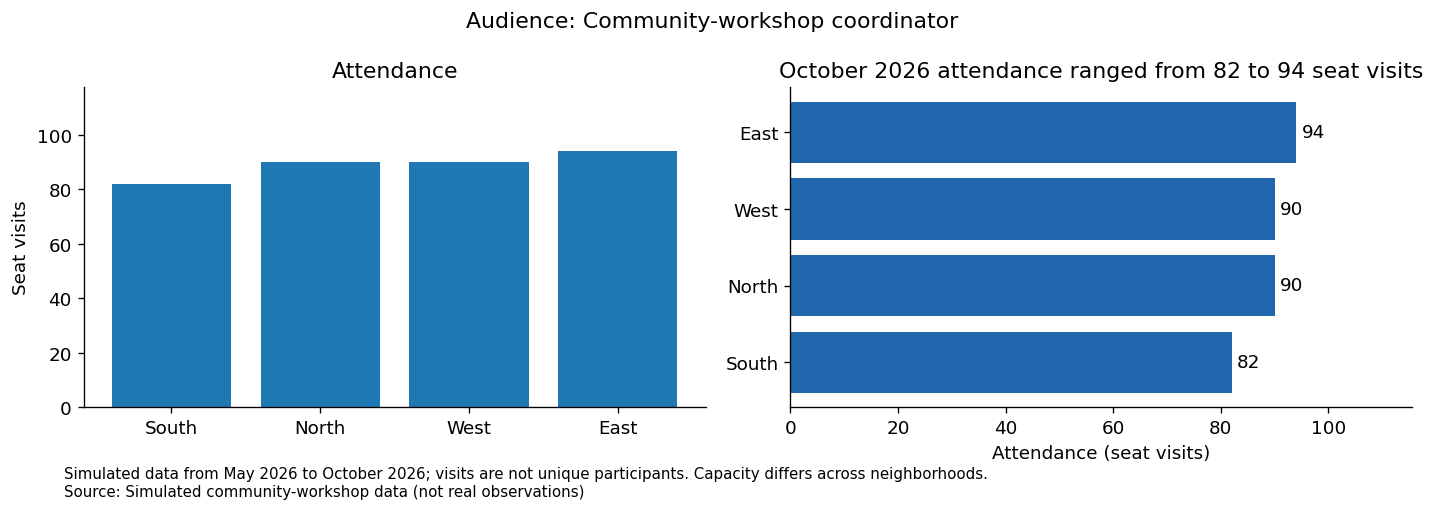

Checked range: 82 to 94


In [19]:
# SECTION 1: MATPLOTLIB CANVAS SETUP

# Initialize a layout with 1 row and 2 columns of subplots.
# figsize=(12, 4) specifies a wide rectangular figure to fit both charts comfortably.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))


# SECTION 2: PLOTTING THE 'BEFORE' CHART (UNOPTIMIZED)

# Render a standard vertical bar chart on the first subplot (axes[0]).
# Using default categorical index labels on the X-axis and raw values on the Y-axis.
axes[0].bar(values.index, values.values, color='tab:blue')

# Add basic configurations: a generic title, Y-axis label, and raw height limits.
# Multiplying by 1.25 pads the plot's ceiling to leave white space above the bars.
axes[0].set(title='Attendance', ylabel='Seat visits', ylim=(0, max(values) * 1.25))


# SECTION 3: PLOTTING THE 'AFTER' CHART (AUDIENCE-FIRST)

# Render a horizontal bar chart on the second subplot (axes[1]) using a cleaner, deep blue color.
# Horizontal orientation facilitates easier categorical reading along the vertical Y-axis.
axes[1].barh(values.index, values.values, color='#2166ac')

# Use our dynamically formulated narrative title and clear explanatory label for the X-axis.
# Max range is scaled by 1.23 to allocate extra space on the right margin for overlaying text labels.
axes[1].set(title=CHART_TITLE, xlabel='Attendance (seat visits)', xlim=(0, max(values) * 1.23))

# Dynamically place value labels next to each horizontal bar for precision.
# We loop over the category indices and values, shifting the label horizontally by +1 unit.
# 'va=center' keeps the numbers vertically aligned with the middle of each bar.
for i, v in enumerate(values):
    axes[1].text(v + 1, i, f'{v:.0f}', va='center')


# SECTION 4: GLOBAL FIGURE ANNOTATION & EXPORT

# Explicitly display the designated target audience above the two plots to set visual context.
fig.suptitle(f'Audience: {AUDIENCE}')

# Append a smaller-font explanatory footnote containing data range details, caveats, and origin source.
# Positional coordinates (0.05, -0.03) are manually adjusted below the figure frame.
fig.text(.05, -.03, CAPTION + '\nSource: ' + SOURCE, fontsize=9)

# Instruct Matplotlib to optimize layout spacing and prevent labels from overlapping axes boundaries.
fig.tight_layout()

# Save the final rendered high-fidelity dual-plot visualization to the output folder.
fig.savefig(OUT / 'm01_before_after.png')

# Display the final plot visual elements in the output frame.
plt.show()


# SECTION 5: GROUND-TRUTH VERIFICATION AND EXPORTS

# Isolate and sort the subset of target-month data to build a clean ground-truth comparison table.
check = selected[['neighborhood', 'attendance_visits', 'capacity_seats']].sort_values('neighborhood')

# Assertion Check 1: Enforce mathematical integrity by verifying total aggregated visits in the plot
# strictly equal the sum of raw rows in our filtered source dataframe.
assert values.sum() == selected.attendance_visits.sum()

# Assertion Check 2: Confirm the visual dataset's neighborhood-sorted elements exactly match the
# numerical array extraction, preventing any visual category mismatching.
assert np.allclose(values.sort_index(), check.attendance_visits.to_numpy())

# Save the verified, audited tabular numbers to a CSV file alongside the visual exports.
check.to_csv(OUT / 'm01_claim_check.csv', index=False)

# Print a diagnostic message reporting the boundaries checked by our programmatic pipeline.
print('Checked range:', int(check.attendance_visits.min()), 'to', int(check.attendance_visits.max()))

### DSC 563 extension — unknown attendance is not zero
DSC 563 students: run the next cell and compare utilization across all months. The observed-month calculation uses attendance and capacity only where attendance is known. The zero-attendance scenario keeps the full capacity denominator and treats missing attendance as zero.

Explain the change in East's percentage and neighborhood ranking. Report its observed-month coverage. The zero-attendance result is a lower-bound scenario, not evidence that nobody attended during the missing month.

BUS 363 and DSC 363 students: skip the next code cell and continue to **Save files for Module 2**.

,observed_periods,total_periods,utilization_pct,zero_imputed_pct
neighborhood,,,,
East,5,6,73.57,62.42
North,6,6,73.17,73.17
South,6,6,80.00,80.00
West,6,6,59.36,59.36


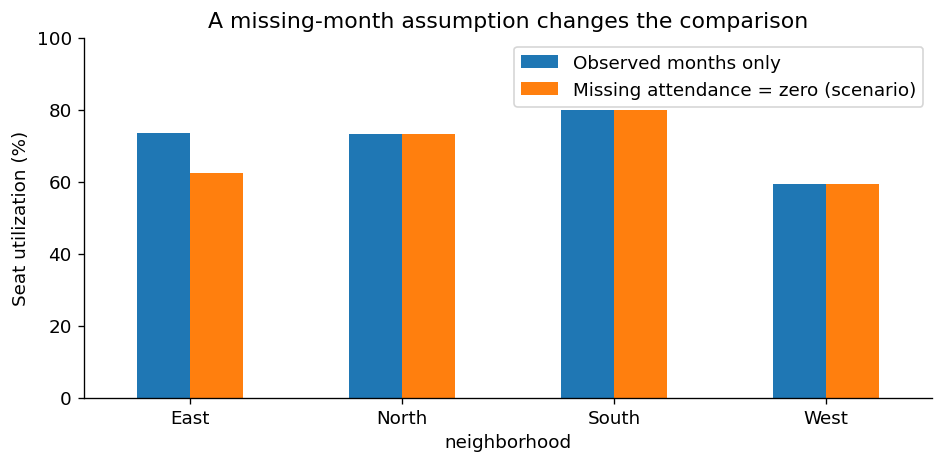

In [20]:
# SECTION 1: METRICS CALCULATION (OBSERVED VS. LOWER-BOUND SCENARIO)

# Create a neighborhood-indexed dataset by running our paired aggregation helper.
# This calculates total observed attendance/capacity across observed months.
summary = paired_summary(data).set_index('neighborhood')

# Calculate a pessimistic lower-bound scenario ('zero-imputed percentage').
# This assumes any missing attendance was zero while dividing by the full, multi-month capacity.
summary['zero_imputed_pct'] = 100 * summary.attendance_visits / summary.capacity_all

# Display a formatted DataFrame of comparative indicators for verification
display(summary[['observed_periods', 'total_periods', 'utilization_pct', 'zero_imputed_pct']].round(2))


# SECTION 2: VISUALIZATION & LAYOUT CONFIGURATION

# Generate a side-by-side grouped bar chart comparing the two metrics across neighborhoods
ax = summary[['utilization_pct', 'zero_imputed_pct']].plot.bar(figsize=(8, 4), ylim=(0, 100))

# Assign descriptive axes labels, title, and legend labels to clearly state assumptions
ax.set(ylabel='Seat utilization (%)', title='A missing-month assumption changes the comparison')
ax.legend(['Observed months only', 'Missing attendance = zero (scenario)'])

# Rotate labels horizontally for readability and optimize subplot padding bounds
plt.xticks(rotation=0)
plt.tight_layout()

# Save the visual plot to our outputs directory and render it in the notebook
plt.savefig(OUT / 'm01_graduate_missingness.png')
plt.show()


# SECTION 3: GROUND-TRUTH VERIFICATION AND AUDIT EXPORTS

# Count East's observed rows directly instead of assuming a fixed count.
expected_east_periods = data.loc[data.neighborhood.eq('East'), 'attendance_visits'].count()
# Confirm the summary preserved that observed coverage.
assert summary.loc['East', 'observed_periods'] == expected_east_periods

# Assertion Check 2: Confirm imputation creates a strictly lower percentage than ignoring the missing period
assert summary.loc['East', 'zero_imputed_pct'] < summary.loc['East', 'utilization_pct']

# Export the calculated metrics table as a CSV file to create a permanent verification record
summary.to_csv(OUT / 'm01_graduate_check.csv')

### Save files for Module 2
All students: run the next cell. It saves the full prepared dataset, a separate copy of your improved chart, the checked attendance values, and a short file guide.

**SAVE THESE FILES for Module 2:** `tableau_workshops_tidy.csv`, `m01_after_chart.png`, `m01_claim_check.csv`, and `module_2_file_guide.txt`.

Open the Colab Files pane, open `outputs`, and download each named file. Save them together on your computer or in Drive. Files left only in the Colab runtime can disappear when the session ends. Use these saved exports in Module 2; their month labels remain the same even if the calendar month changes.

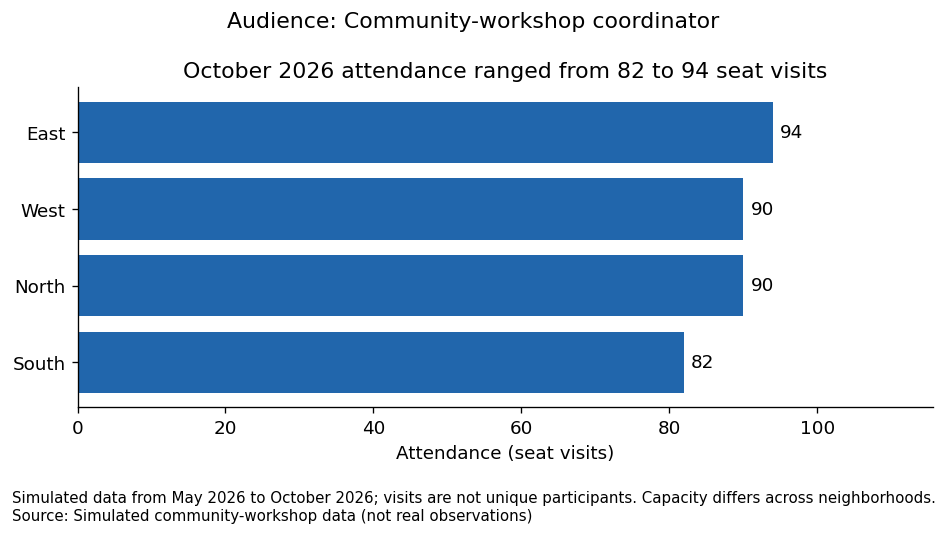

SAVE THESE FILES for Module 2: tableau_workshops_tidy.csv, m01_after_chart.png, m01_claim_check.csv, module_2_file_guide.txt


In [21]:
# Copy the prepared dataset so exporting dates does not change the working data.
tableau_data = data.copy()
# Write dates in a consistent format that Tableau can read as calendar dates.
tableau_data['month'] = tableau_data.month.dt.strftime('%Y-%m-%d')
# Save every month, including the row with missing attendance needed for the graduate task.
tableau_data.to_csv(OUT / 'tableau_workshops_tidy.csv', index=False)

# Include the selected month with each checked value so exports can be matched later.
claim_check = selected[['month', 'neighborhood', 'attendance_visits', 'capacity_seats']].sort_values('neighborhood').copy()
# Format the checked month in the same way as the complete dataset.
claim_check['month'] = claim_check.month.dt.strftime('%Y-%m-%d')
# Save checked source values for comparison with the student's actual Tableau results.
claim_check.to_csv(OUT / 'm01_claim_check.csv', index=False)

# Create a separate figure showing only the improved chart for the Module 2 comparison.
after_fig, after_ax = plt.subplots(figsize=(8, 4))
# Preserve the same categories, values, and ordering as the improved Module 1 chart.
after_ax.barh(values.index, values.values, color='#2166ac')
# Derive the axis limit from the data and retain a zero baseline.
after_ax.set(title=CHART_TITLE, xlabel='Attendance (seat visits)', xlim=(0, values.max() * 1.23))
# Derive label spacing from the displayed values instead of assuming a fixed attendance scale.
label_offset = values.max() * 0.01
# Add the value next to each bar so the numbers can be compared in Tableau.
for position, attendance_value in enumerate(values):
    # Format visit counts as whole numbers without changing the underlying values.
    after_ax.text(attendance_value + label_offset, position, f'{attendance_value:.0f}', va='center')
# Identify the audience above the chart.
after_fig.suptitle(f'Audience: {AUDIENCE}')
# Keep the caveat and source visible in the exported image.
after_fig.text(0.02, -0.08, CAPTION + '\nSource: ' + SOURCE, fontsize=9)
# Adjust the chart layout before saving.
after_fig.tight_layout()
# Save the standalone improved chart for the next module.
after_fig.savefig(OUT / 'm01_after_chart.png')
# Display the exact chart that was exported.
plt.show()

# Read the CSV back to check that the date labels and all rows survived the export.
export_check = pd.read_csv(OUT / 'tableau_workshops_tidy.csv', parse_dates=['month'])
# Verify the saved table matches the prepared data, allowing CSV numeric type conversion.
pd.testing.assert_frame_equal(export_check, data, check_dtype=False)
# Verify the saved reference values still match the plotted neighborhood values.
assert np.allclose(claim_check.set_index('neighborhood').attendance_visits.sort_index(), values.sort_index())

# Build a student file guide from this run's actual date range and selected month.
file_guide = f'''SAVE THESE FILES for Module 2.
Data source: {SOURCE}
Simulated period: {START_DATE:%B %Y} to {END_DATE:%B %Y}
Selected chart month: {pd.Timestamp(SELECTED_MONTH):%B %Y}

tableau_workshops_tidy.csv: Import this complete dataset into Tableau.
m01_after_chart.png: Compare your Tableau chart with this improved Python chart.
m01_claim_check.csv: Compare the actual Tableau values with these checked values.

In Tableau, use the selected month shown above for the attendance chart.
For the DSC 563 extension, use all months in the dataset and the observed-month calculations in the Module 2 directions.
Keep the saved files together. Do not change month labels to the current month in Module 2.
Follow the Module 2 Moodle directions for the Tableau task and submission.
'''
# Save the guide beside the data and chart so it travels with the exported files.
(OUT / 'module_2_file_guide.txt').write_text(file_guide, encoding='utf-8')
# Print a direct reminder after all required files have been created and checked.
print('SAVE THESE FILES for Module 2: tableau_workshops_tidy.csv, m01_after_chart.png, m01_claim_check.csv, module_2_file_guide.txt')


### Sources and presentation evidence
Phillips's *The magical science of storytelling* is required course resource; use its technique as a design choice, not proof that a chart caused behavior. [Matplotlib bar charts](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.bar.html) supplies syntax. Present the before/after visual, verified range, audience decision, and limitation. Graduate students add the missingness comparison and a second substantive source.

### Brief disclosure and dated export record

In [22]:
# SECTION 1: AI-USE HONEST DISCLOSURE AND AUDIT METADATA

# Self-declaration record for tracking AI tool utilization during analysis.
# Honestly document if an AI was used, which tool, what was permitted, and checks performed.
AI_USE = {'used': False,
          'tool': '', # identify the tool by adding the name inside the single quotes
          'permitted_help': '',  # identify the help by adding the information inside the single quotes
          'checks_performed': ''}

# Assemble a high-level operational record documenting pipeline provenance.
# Contains data origin, the active data snapshot timestamp, UTC runtime, and the AI declaration dictionary.
record = {
    'source': SOURCE,
    'source_snapshot': SNAPSHOT_DATE,
    'run_utc': datetime.now(timezone.utc).isoformat(),
    'ai_use': AI_USE
}


# SECTION 2: DISK EXPORT AND FILE VERIFICATION

# Serialize the metadata record structure into an indented JSON format and write to the output folder
(OUT / 'run_record.json').write_text(json.dumps(record, indent=2))

# Scan the active output directory, filter only for files, and list them to confirm exports succeeded
print('Output files:', ', '.join(p.name for p in sorted(OUT.iterdir()) if p.is_file()))

Output files: m01_after_chart.png, m01_before_after.png, m01_claim_check.csv, m01_graduate_check.csv, m01_graduate_missingness.png, module_2_file_guide.txt, run_record.json, tableau_workshops_tidy.csv


### Export, present, and share
1. Save your personal notebook in Google Drive. Before submitting, restart the runtime and run the required cells in order. DSC 563 students also run the graduate extension.
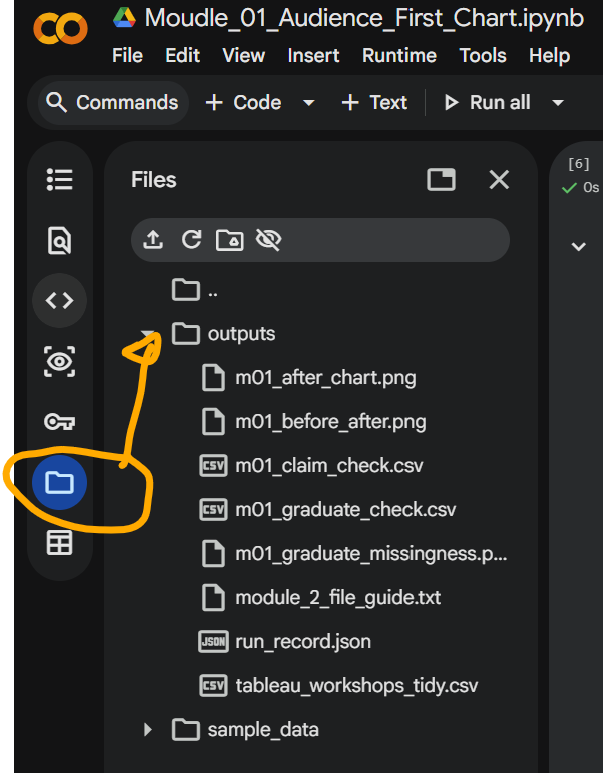
2. Download `m01_before_after.png` for your Module 1 presentation. DSC 563 students also download `m01_graduate_missingness.png` and `m01_graduate_check.csv`.
3. **SAVE THESE FILES for Module 2:** `tableau_workshops_tidy.csv`, `m01_after_chart.png`, `m01_claim_check.csv`, and `module_2_file_guide.txt`. Download them from `outputs` and keep them together.
4. Present your visualizations and reasoning in the Module 1 VoiceThread. Show the before/after charts, checked values, audience decision, and limitation. Follow the Moodle directions for citations, AI disclosure, points, and presentation length.
5. Share your personal notebook with the instructor as Editor using the address in the course sharing guide. Check access, then add the notebook URL, course section, and module label in a Text comment on the first slide.
6. DSC 563 students: explain the missing-data comparison and use at least two distinct credible sources, including a required resource. Software documentation alone does not support a substantive claim.
7. Module 2 uses Tableau and the saved Module 1 exports. A new Python notebook for Moudle 2 is *not* required.

In [23]:
# Give this notebook access to my Google Drive files for easier uploading of coursework.

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **Module 02: Documentation of Existing Work**

GitHub Repository: https://github.com/jasirard/DSC563

Python chart recreation using Tableau

(*Selected month/year = October 2026*).

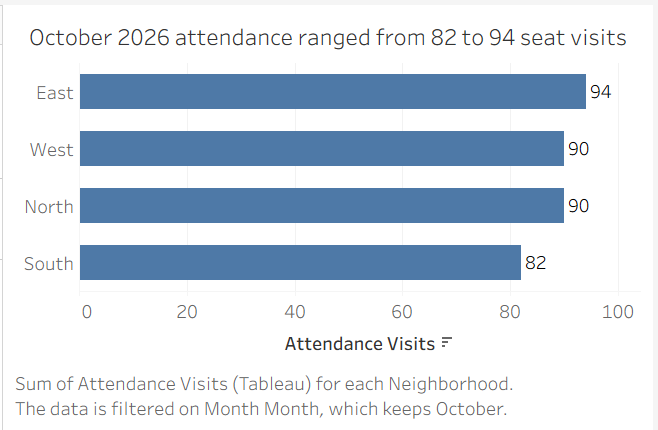


Confirmation of matching values for Tableau and Collab charts.


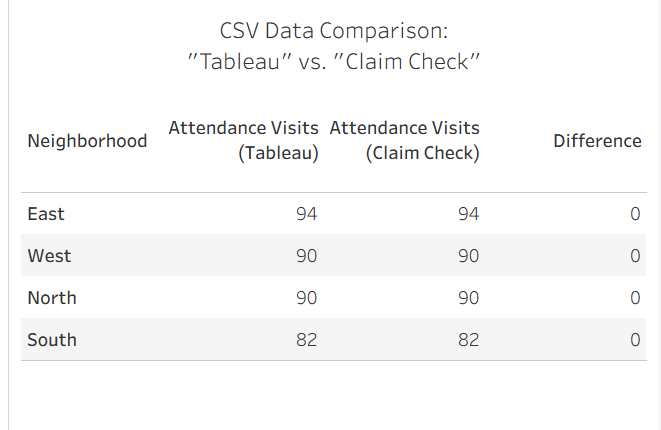


Weighted values (monthly vs. capacity) for Module 02.


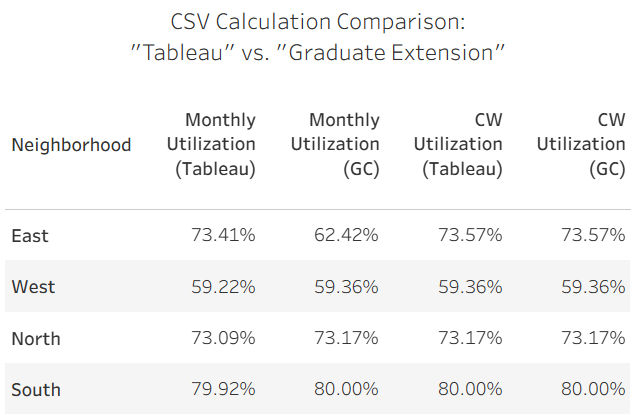


Comparison of weighted values among both .csv files.


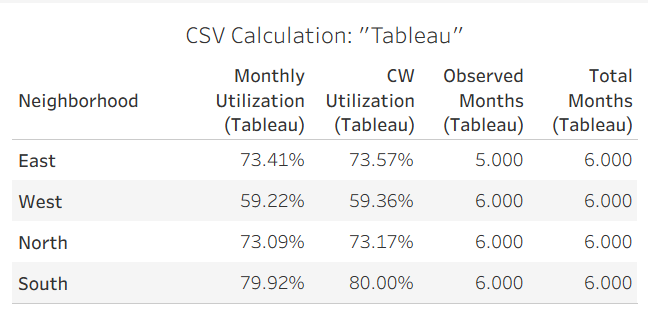

In [24]:
# ORIGINAL PROMPT:
# Import "tableau_workshops_tidy.csv" from the mounted Google Drive.
# Evaluate seat utilization.
# For each neighborhood, describe monthly utilization and capacity-weighted utilization.
# For the 2nd printed table, reorder the neighborhoods in the left column,
# so that from top to bottom they are listed East, West, North, and South.

import pandas as pd
import numpy as np

# 1. Load dataset from Google Drive
file_path = '/content/drive/MyDrive/tableau_workshops_tidy.csv'
df = pd.read_csv(file_path)

# Convert month to datetime for sorting and clean labels
df['month'] = pd.to_datetime(df['month'])

# Define the custom neighborhood ordering
neighborhood_order = ['East', 'West', 'North', 'South']

# 2. Monthly utilization per neighborhood
# Since some values might be missing (like East's second month), we evaluate it as observed.
df['monthly_utilization'] = 100 * df['attendance_visits'] / df['capacity_seats']

print("--- Observed Monthly Utilization (%) by Neighborhood ---")
monthly_pivot = df.pivot(index='month', columns='neighborhood', values='monthly_utilization')
monthly_pivot.index = monthly_pivot.index.strftime('%B %Y')

# Reorder columns of the pivot table to match the neighborhood order
monthly_pivot = monthly_pivot.reindex(columns=neighborhood_order)
display(monthly_pivot.round(2))

# 3. Overall Capacity-Weighted Utilization per neighborhood
# This correctly aggregates only the observed periods: sum(attendance) / sum(capacity_for_observed_periods)
valid_df = df.dropna(subset=['attendance_visits'])
weighted_util = valid_df.groupby('neighborhood', group_keys=False).apply(
    lambda x: 100 * x['attendance_visits'].sum() / x['capacity_seats'].sum(),
    include_groups=False
).rename('capacity_weighted_utilization_pct')

# Simple average of monthly utilizations for comparison (unweighted)
simple_avg_util = df.groupby('neighborhood')['monthly_utilization'].mean().rename('simple_average_utilization_pct')

summary_df = pd.concat([weighted_util, simple_avg_util], axis=1)

# Reorder the rows of the summary table to match the neighborhood order
summary_df = summary_df.reindex(neighborhood_order)

print("\n--- Overall Neighborhood Seat Utilization Metrics (%) ---")
display(summary_df.round(2))

--- Observed Monthly Utilization (%) by Neighborhood ---


neighborhood,East,West,North,South
month,,,,
May 2026,70.00,55.00,75.00,80.00
June 2026,NaN,58.33,70.00,77.50
July 2026,70.00,56.92,70.00,80.00
August 2026,74.55,60.77,74.00,77.78
September 2026,74.17,60.00,74.55,82.22
October 2026,78.33,64.29,75.00,82.00



--- Overall Neighborhood Seat Utilization Metrics (%) ---


,capacity_weighted_utilization_pct,simple_average_utilization_pct
neighborhood,,
East,73.57,73.41
West,59.36,59.22
North,73.17,73.09
South,80.00,79.92
